# Explainable 1D-CNN and Machine Learning Framework for Encrypted Network Traffic Classification: A Comparative Study Using SHAP, LIME, and FGSM

### Project Overview

**Project:** Explainable and Adversarially Evaluated Encrypted Network Traffic Classification

**Group Members:**
- 1032231245 – Shreyansh Mohanty
- 1032233120 – Aditi Singh
- 1032233163 – Harshita Shah
- 1032230890 – Vinikesh Hiranandani

**Dataset:** Real ISCX VPN-nonVPN network traffic dataset, using the 15-second time-based flow feature CSV.

- Total samples: 18,758
- Original features: 23 statistical flow features
- Target classes: VPN and Non-VPN
- Class distribution:
  - VPN: 9,793
  - Non-VPN: 8,965
- Missing values: 0

**Classification Models:**
- Random Forest
- Original 1D-CNN
- Improved 1D-CNN

**Feature Selection:**

Mutual Information-based feature selection using `SelectKBest`:

- Algorithm: `mutual_info_classif`
- Original features: 23
- Selected features: 15
- Dimensionality reduction: 34.78%
- Feature selection fitted only on training data.

**Model Input:**
- Random Forest: 15 selected features.
- Original 1D-CNN: 15 selected features reshaped to (15, 1).
- Improved 1D-CNN: 15 selected features reshaped to (15, 1).

**Explainable AI Methods:**
- **SHAP:** Global feature importance and feature contribution analysis.
- **LIME:** Local, instance-level prediction explanations.

**Adversarial Evaluation:**
- Fast Gradient Sign Method (FGSM).
- Perturbation strengths: 0, 0.01, 0.05, 0.10, 0.15, 0.20 and 0.30.
- Evaluation of CNN sensitivity to adversarial perturbations.

**Experimental Environment:** Google Colab, Python, TensorFlow, Scikit-learn, SHAP and LIME.

---

## Table of Contents

1. Introduction
2. Literature Review
3. Problem Statement and Research Objectives
4. Dataset Description
   - 4.1 ISCX VPN-nonVPN Dataset
   - 4.2 Dataset Features and Class Distribution
   - 4.3 Exploratory Data Analysis
5. Data Preprocessing
   - 5.1 Handling Missing and Infinite Values
   - 5.2 Label Encoding
   - 5.3 Training, Validation and Testing Split
   - 5.4 Feature Standardization
6. Feature Selection Using Mutual Information
   - 6.1 Mutual Information Feature Scoring
   - 6.2 Selection of Top 15 Features
   - 6.3 Feature Importance Analysis
7. Classification Model Development
   - 7.1 Random Forest Classifier
   - 7.2 Original 1D-CNN
   - 7.3 Improved 1D-CNN
8. Model Training and Evaluation
   - 8.1 Training Configuration
   - 8.2 Accuracy, Precision, Recall and F1-Score
   - 8.3 Confusion Matrix Analysis
   - 8.4 ROC Curve and AUC Analysis
   - 8.5 Training Time Comparison
9. Explainable AI Analysis
   - 9.1 SHAP Global Feature Importance
   - 9.2 LIME Local Prediction Explanation
10. Adversarial Robustness Evaluation
    - 10.1 FGSM Attack Methodology
    - 10.2 Perturbation Strengths
    - 10.3 Adversarial Accuracy Analysis
11. Comparative Results and Discussion
12. Limitations and Future Scope
13. Conclusion
14. References

In [47]:
import zipfile
import os

zip_path = "/content/ISCX_VPN_nonVPN_real_CSVs.zip"
extract_path = "/content/ISCX_REAL_DATA"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['TimeBasedFeatures-Dataset-30s-VPN.csv', 'TimeBasedFeatures-Dataset-120s-VPN.csv', 'TimeBasedFeatures-Dataset-15s-VPN.csv', 'TimeBasedFeatures-Dataset-60s-VPN.csv']


In [48]:
import pandas as pd
import numpy as np

DATA_PATH = "/content/ISCX_REAL_DATA/TimeBasedFeatures-Dataset-15s-VPN.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df["class1"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

display(df.head())

Dataset loaded successfully!
Dataset shape: (18758, 24)

Column names:
['duration', 'total_fiat', 'total_biat', 'min_fiat', 'min_biat', 'max_fiat', 'max_biat', 'mean_fiat', 'mean_biat', 'flowPktsPerSecond', 'flowBytesPerSecond', 'min_flowiat', 'max_flowiat', 'mean_flowiat', 'std_flowiat', 'min_active', 'mean_active', 'max_active', 'std_active', 'min_idle', 'mean_idle', 'max_idle', 'std_idle', 'class1']

Class distribution:
class1
VPN        9793
Non-VPN    8965
Name: count, dtype: int64

Missing values:
0


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,...,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,class1
0,9368711,16,4,1564818,1549373,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,...,267600.198443,1871488,1.983656e+06,2195089,1.832197e+05,1234883,1420565.0,1523088,161096.539275,Non-VPN
1,7340238,18,4,1567554,1527893,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,...,221462.862028,1491627,3.572433e+06,5653239,2.942704e+06,1131498,1324636.0,1517774,273138.379008,Non-VPN
2,4644225,29,15,1270547,1079974,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,...,217475.425246,1758922,1.758922e+06,1758922,0.000000e+00,1079974,1079974.0,1079974,0.000000,Non-VPN
3,4978735,19,8,2492050,2457286,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,...,436959.716436,1710925,2.382905e+06,3054885,9.503232e+05,1346073,1894031.5,2441990,774930.342317,Non-VPN
4,11838189,19,10,3094089,3093543,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,...,436129.639296,1747431,2.400446e+06,3240696,6.232744e+05,1394455,1983227.0,3042717,725987.829075,Non-VPN


In [49]:
# STEP 4: DATA PREPROCESSING

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# 1. Separate features and target
X = df.drop(columns=["class1"]).copy()
y = df["class1"].copy()

# 2. Handle infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# 3. Check missing values
print("Missing values before handling:", X.isnull().sum().sum())

# 4. Fill missing values, if any
X = X.fillna(X.median())

# 5. Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nClass mapping:")
for i, name in enumerate(label_encoder.classes_):
    print(name, "=", i)

# 6. Split data: 80% train, 10% validation, 10% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# 7. Feature scaling (fit only on training data)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("\nPREPROCESSING COMPLETED")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)
print("Number of features:", X_train_scaled.shape[1])
print("Number of classes:", len(label_encoder.classes_))

Missing values before handling: 0

Class mapping:
Non-VPN = 0
VPN = 1

PREPROCESSING COMPLETED
Training: (15006, 23)
Validation: (1876, 23)
Testing: (1876, 23)
Number of features: 23
Number of classes: 2


In [50]:
# STEP 5: MUTUAL INFORMATION FEATURE SELECTION

from sklearn.feature_selection import SelectKBest, mutual_info_classif

# Select top 15 features
feature_selector = SelectKBest(
    score_func=mutual_info_classif,
    k=15
)

# Fit only on training data
X_train_selected = feature_selector.fit_transform(
    X_train_scaled, y_train
)

# Transform validation and test data
X_val_selected = feature_selector.transform(X_val_scaled)
X_test_selected = feature_selector.transform(X_test_scaled)

# Get selected feature names
selected_indices = feature_selector.get_support(indices=True)

selected_feature_names = X.columns[selected_indices]

print("Original features:", X_train_scaled.shape[1])
print("Selected features:", X_train_selected.shape[1])
print("Dimensionality reduction:",
      round((1 - 15/23) * 100, 2), "%")

print("\nSelected Features:")
print(selected_feature_names.tolist())

# Save feature scores
feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Mutual_Information_Score": feature_selector.scores_,
    "Selected": feature_selector.get_support()
}).sort_values(
    by="Mutual_Information_Score",
    ascending=False
)

display(feature_scores)

feature_scores.to_csv(
    "mutual_information_feature_scores.csv",
    index=False
)

Original features: 23
Selected features: 15
Dimensionality reduction: 34.78 %

Selected Features:
['duration', 'total_fiat', 'total_biat', 'min_fiat', 'min_biat', 'max_fiat', 'max_biat', 'mean_fiat', 'mean_biat', 'flowPktsPerSecond', 'flowBytesPerSecond', 'min_flowiat', 'max_flowiat', 'mean_flowiat', 'std_flowiat']


,Feature,Mutual_Information_Score,Selected
9,flowPktsPerSecond,0.214089,True
13,mean_flowiat,0.212897,True
5,max_fiat,0.188222,True
2,total_biat,0.184798,True
6,max_biat,0.181423,True
12,max_flowiat,0.173570,True
10,flowBytesPerSecond,0.171661,True
3,min_fiat,0.157398,True
0,duration,0.138906,True
11,min_flowiat,0.136988,True


In [51]:
# STEP 6: PREPARE MODEL INPUTS

# Random Forest inputs
X_train_rf = X_train_selected
X_val_rf = X_val_selected
X_test_rf = X_test_selected

# CNN inputs: reshape into 3D
X_train_cnn = X_train_selected.reshape(-1, 15, 1)
X_val_cnn = X_val_selected.reshape(-1, 15, 1)
X_test_cnn = X_test_selected.reshape(-1, 15, 1)

print("Random Forest input:", X_train_rf.shape)
print("CNN training input:", X_train_cnn.shape)
print("CNN validation input:", X_val_cnn.shape)
print("CNN testing input:", X_test_cnn.shape)

print("\nAll model inputs prepared successfully!")

Random Forest input: (15006, 15)
CNN training input: (15006, 15, 1)
CNN validation input: (1876, 15, 1)
CNN testing input: (1876, 15, 1)

All model inputs prepared successfully!


In [52]:
# STEP 7: TRAIN RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

import time

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(X_train_rf, y_train)

rf_training_time = time.time() - start_time

# Validation predictions
y_val_rf = rf_model.predict(X_val_rf)

rf_val_accuracy = accuracy_score(y_val, y_val_rf)

print("Random Forest training completed!")
print("Validation Accuracy:", round(rf_val_accuracy * 100, 2), "%")
print("Training Time:", round(rf_training_time, 2), "seconds")

print("\nValidation Classification Report:")
print(classification_report(
    y_val,
    y_val_rf,
    target_names=label_encoder.classes_
))

Random Forest training completed!
Validation Accuracy: 92.0 %
Training Time: 14.84 seconds

Validation Classification Report:
              precision    recall  f1-score   support

     Non-VPN       0.93      0.90      0.91       896
         VPN       0.91      0.94      0.92       980

    accuracy                           0.92      1876
   macro avg       0.92      0.92      0.92      1876
weighted avg       0.92      0.92      0.92      1876



In [53]:
# STEP 8: BUILD AND TRAIN 1D-CNN

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, Flatten,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping
import time

cnn_model = Sequential([
    Conv1D(64, kernel_size=3, activation="relu",
           input_shape=(15, 1)),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(128, kernel_size=3, activation="relu"),
    BatchNormalization(),

    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

start_time = time.time()

history = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

cnn_training_time = time.time() - start_time

print("\nCNN training completed!")
print("Training Time:", round(cnn_training_time, 2), "seconds")

Epoch 1/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.6281 - loss: 0.6629 - val_accuracy: 0.5155 - val_loss: 0.6957
Epoch 2/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6709 - loss: 0.5965 - val_accuracy: 0.6429 - val_loss: 0.6237
Epoch 3/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6782 - loss: 0.5775 - val_accuracy: 0.7015 - val_loss: 0.5613
Epoch 4/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6857 - loss: 0.5698 - val_accuracy: 0.6898 - val_loss: 0.5560
Epoch 5/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6935 - loss: 0.5617 - val_accuracy: 0.6956 - val_loss: 0.5691
Epoch 6/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6973 - loss: 0.5517 - val_accuracy: 0.7095 - val_loss: 0.5556
Epoch 7/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7025 - loss: 0.5499 - val_accuracy: 0.7180 - val_loss: 0.5562
Epoch 8/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7082 - loss: 0.5395 - val_accuracy: 

In [54]:
# STEP 9: TEST SET EVALUATION

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Random Forest predictions
y_test_rf = rf_model.predict(X_test_rf)
rf_probabilities = rf_model.predict_proba(X_test_rf)[:, 1]

# CNN predictions
cnn_probabilities = cnn_model.predict(X_test_cnn).ravel()
y_test_cnn = (cnn_probabilities >= 0.5).astype(int)

# Accuracy
rf_test_accuracy = accuracy_score(y_test, y_test_rf)
cnn_test_accuracy = accuracy_score(y_test, y_test_cnn)

print("RANDOM FOREST TEST ACCURACY:",
      round(rf_test_accuracy * 100, 2), "%")

print("CNN TEST ACCURACY:",
      round(cnn_test_accuracy * 100, 2), "%")

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test, y_test_rf,
    target_names=label_encoder.classes_
))

print("\nCNN CLASSIFICATION REPORT")
print(classification_report(
    y_test, y_test_cnn,
    target_names=label_encoder.classes_
))

print("Random Forest ROC-AUC:",
      round(roc_auc_score(y_test, rf_probabilities), 4))

print("CNN ROC-AUC:",
      round(roc_auc_score(y_test, cnn_probabilities), 4))

59/59 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step
RANDOM FOREST TEST ACCURACY: 91.79 %
CNN TEST ACCURACY: 71.48 %

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Non-VPN       0.93      0.90      0.91       897
         VPN       0.91      0.93      0.92       979

    accuracy                           0.92      1876
   macro avg       0.92      0.92      0.92      1876
weighted avg       0.92      0.92      0.92      1876


CNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Non-VPN       0.70      0.71      0.70       897
         VPN       0.73      0.72      0.73       979

    accuracy                           0.71      1876
   macro avg       0.71      0.71      0.71      1876
weighted avg       0.71      0.71      0.71      1876

Random Forest ROC-AUC: 0.9765
CNN ROC-AUC: 0.8025


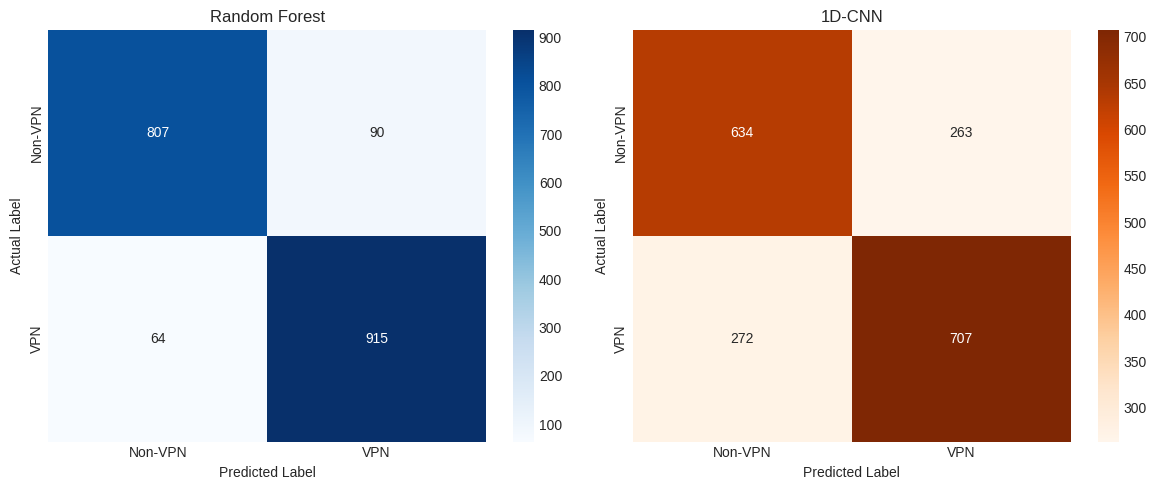

In [55]:
# STEP 11: CONFUSION MATRIX COMPARISON

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Random Forest
rf_cm = confusion_matrix(y_test, y_test_rf)

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[0]
)

axes[0].set_title("Random Forest")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# CNN
cnn_cm = confusion_matrix(y_test, y_test_cnn)

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[1]
)

axes[1].set_title("1D-CNN")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [56]:
!pip install shap

In [57]:
# STEP 12: SHAP EXPLAINABILITY

import shap
import numpy as np
import pandas as pd

# Use a sample of test data to keep SHAP computation manageable
X_shap = pd.DataFrame(
    X_test_rf[:300],
    columns=selected_feature_names
)

# Create SHAP explainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")
print("SHAP output type:", type(shap_values))

SHAP values calculated successfully!
SHAP output type: <class 'numpy.ndarray'>


In [58]:
# STEP 13: SHAP SUMMARY PLOT

# Handle SHAP output dimensions
if isinstance(shap_values, list):
    shap_to_plot = shap_values[1]
elif shap_values.ndim == 3:
    shap_to_plot = shap_values[:, :, 1]
else:
    shap_to_plot = shap_values

shap.summary_plot(
    shap_to_plot,
    X_shap,
    feature_names=selected_feature_names,
    show=True
)

[Plot removed to save space; the saved image is in results/original_run/]

In [59]:
# STEP 14: INSTALL AND IMPORT LIME

!pip install lime

from lime.lime_tabular import LimeTabularExplainer
import numpy as np

lime_explainer = LimeTabularExplainer(
    training_data=X_train_selected,
    feature_names=list(selected_feature_names),
    class_names=list(label_encoder.classes_),
    mode="classification",
    discretize_continuous=True
)

print("LIME explainer created successfully!")

LIME explainer created successfully!


In [60]:
# STEP 15: LIME INDIVIDUAL EXPLANATION

# Select one test sample
sample_index = 0

sample = X_test_selected[sample_index]

# Generate LIME explanation
lime_explanation = lime_explainer.explain_instance(
    data_row=sample,
    predict_fn=rf_model.predict_proba,
    num_features=10
)

# Display explanation
print("Actual class:",
      label_encoder.inverse_transform([y_test[sample_index]])[0])

print("Predicted class:",
      label_encoder.inverse_transform(
          [rf_model.predict(sample.reshape(1, -1))[0]]
      )[0])

lime_explanation.show_in_notebook()

Actual class: Non-VPN
Predicted class: Non-VPN


<IPython.core.display.HTML object>

In [61]:
# STEP 16: FGSM ADVERSARIAL ATTACK

import tensorflow as tf
import numpy as np

def fgsm_attack(model, images, labels, epsilon):
    images = tf.convert_to_tensor(images, dtype=tf.float32)
    labels = tf.convert_to_tensor(labels, dtype=tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(images)

        predictions = model(images, training=False)
        predictions = tf.reshape(predictions, [-1])

        loss = tf.keras.losses.binary_crossentropy(
            labels, predictions
        )
        loss = tf.reduce_mean(loss)

    gradients = tape.gradient(loss, images)

    adversarial_images = (
        images + epsilon * tf.sign(gradients)
    )

    return adversarial_images.numpy()


# Generate adversarial samples
epsilon = 0.05

X_test_adversarial = fgsm_attack(
    cnn_model,
    X_test_cnn,
    y_test,
    epsilon
)

print("FGSM adversarial samples generated!")
print("Original test shape:", X_test_cnn.shape)
print("Adversarial test shape:", X_test_adversarial.shape)
print("Epsilon:", epsilon)

FGSM adversarial samples generated!
Original test shape: (1876, 15, 1)
Adversarial test shape: (1876, 15, 1)
Epsilon: 0.05


In [62]:
# STEP 17: EVALUATE FGSM ROBUSTNESS

from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np

epsilon_values = [0, 0.01, 0.05, 0.10, 0.15, 0.20, 0.30]

robustness_results = []

for eps in epsilon_values:

    if eps == 0:
        X_adv = X_test_cnn
    else:
        X_adv = fgsm_attack(
            cnn_model,
            X_test_cnn,
            y_test,
            eps
        )

    predictions = cnn_model.predict(
        X_adv, verbose=0
    ).ravel()

    predicted_labels = (predictions >= 0.5).astype(int)

    accuracy = accuracy_score(
        y_test,
        predicted_labels
    )

    robustness_results.append({
        "Epsilon": eps,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

robustness_df = pd.DataFrame(robustness_results)

print("FGSM ROBUSTNESS RESULTS")
display(robustness_df)

FGSM ROBUSTNESS RESULTS


,Epsilon,Accuracy (%)
0,0.00,71.48
1,0.01,41.68
2,0.05,21.96
3,0.10,20.90
4,0.15,34.59
5,0.20,30.65
6,0.30,33.74


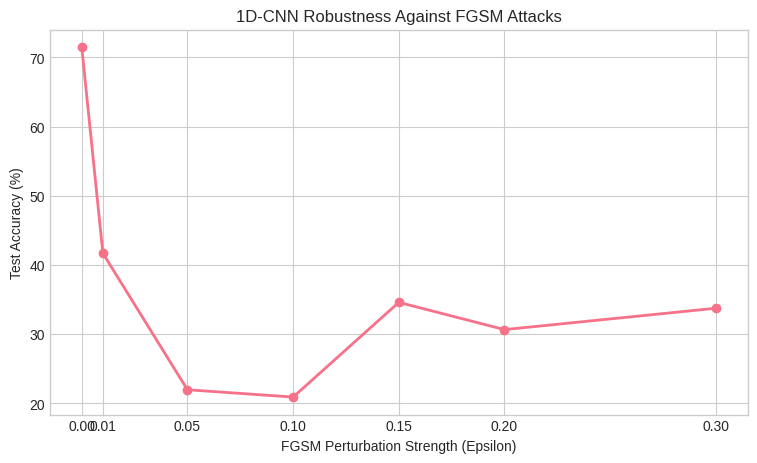

In [63]:
# STEP 18: FGSM ROBUSTNESS GRAPH

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    robustness_df["Epsilon"],
    robustness_df["Accuracy (%)"],
    marker="o",
    linewidth=2
)

plt.title("1D-CNN Robustness Against FGSM Attacks")
plt.xlabel("FGSM Perturbation Strength (Epsilon)")
plt.ylabel("Test Accuracy (%)")
plt.xticks(epsilon_values)
plt.grid(True)

plt.show()

In [64]:
# STEP 19: SAVE EXPERIMENTAL RESULTS

import os
import pandas as pd
import joblib

os.makedirs("/content/Research_Results", exist_ok=True)

# 1. Save model comparison
comparison = pd.DataFrame({
    "Model": ["Random Forest", "1D-CNN"],
    "Test Accuracy (%)": [
        rf_test_accuracy * 100,
        cnn_test_accuracy * 100
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, cnn_probabilities)
    ],
    "Training Time (seconds)": [
        rf_training_time,
        cnn_training_time
    ]
})

comparison.to_csv(
    "/content/Research_Results/model_comparison.csv",
    index=False
)

# 2. Save FGSM results
robustness_df.to_csv(
    "/content/Research_Results/fgsm_results.csv",
    index=False
)

# 3. Save trained models
joblib.dump(
    rf_model,
    "/content/Research_Results/random_forest.pkl"
)

cnn_model.save(
    "/content/Research_Results/cnn_model.keras"
)

# 4. Save preprocessing objects
joblib.dump(scaler, "/content/Research_Results/scaler.pkl")
joblib.dump(feature_selector, "/content/Research_Results/feature_selector.pkl")
joblib.dump(label_encoder, "/content/Research_Results/label_encoder.pkl")

print("All experimental results and models saved!")
print(os.listdir("/content/Research_Results"))

All experimental results and models saved!
['label_encoder.pkl', 'fgsm_results.csv', 'random_forest.pkl', 'scaler.pkl', 'model_comparison.csv', 'cnn_model.keras', 'feature_selector.pkl']


In [65]:
# STEP 20: IMPROVED 1D-CNN

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, GlobalMaxPooling1D,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import time

improved_cnn = Sequential([
    Input(shape=(15, 1)),

    Conv1D(32, kernel_size=3, padding="same",
           activation="relu", kernel_regularizer=l2(0.001)),
    BatchNormalization(),

    Conv1D(64, kernel_size=3, padding="same",
           activation="relu", kernel_regularizer=l2(0.001)),
    BatchNormalization(),

    GlobalMaxPooling1D(),

    Dense(64, activation="relu"),
    Dropout(0.4),

    Dense(32, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

improved_cnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

start_time = time.time()

improved_history = improved_cnn.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=40,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

improved_cnn_time = time.time() - start_time

print("\nImproved CNN training completed!")
print("Training time:", round(improved_cnn_time, 2), "seconds")

Epoch 1/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.5668 - loss: 0.7483 - val_accuracy: 0.5314 - val_loss: 0.7291 - learning_rate: 0.0010
Epoch 2/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6121 - loss: 0.6981 - val_accuracy: 0.5592 - val_loss: 0.6973 - learning_rate: 0.0010
Epoch 3/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6302 - loss: 0.6767 - val_accuracy: 0.6551 - val_loss: 0.6496 - learning_rate: 0.0010
Epoch 4/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6376 - loss: 0.6628 - val_accuracy: 0.6493 - val_loss: 0.6510 - learning_rate: 0.0010
Epoch 5/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6491 - loss: 0.6519 - val_accuracy: 0.6620 - val_loss: 0.6283 - learning_rate: 0.0010
Epoch 6/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6528 - loss: 0.6402 - val_accuracy: 0.6631 - val_loss: 0.6318 - learning_rate: 0.0010
Epoch 7/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6687 - loss: 0.6280 

In [66]:
# STEP 21: EVALUATE IMPROVED CNN

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

# Predict probabilities
improved_probabilities = improved_cnn.predict(
    X_test_cnn
).ravel()

# Convert probabilities to class labels
improved_predictions = (
    improved_probabilities >= 0.5
).astype(int)

# Calculate metrics
improved_accuracy = accuracy_score(
    y_test,
    improved_predictions
)

improved_auc = roc_auc_score(
    y_test,
    improved_probabilities
)

print("IMPROVED CNN TEST ACCURACY:",
      round(improved_accuracy * 100, 2), "%")

print("IMPROVED CNN ROC-AUC:",
      round(improved_auc, 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    improved_predictions,
    target_names=label_encoder.classes_
))

59/59 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step
IMPROVED CNN TEST ACCURACY: 72.55 %
IMPROVED CNN ROC-AUC: 0.8159

Classification Report:
              precision    recall  f1-score   support

     Non-VPN       0.68      0.82      0.74       897
         VPN       0.79      0.64      0.71       979

    accuracy                           0.73      1876
   macro avg       0.73      0.73      0.72      1876
weighted avg       0.74      0.73      0.72      1876



,Model,Test Accuracy (%),ROC-AUC,Training Time (seconds)
0,Random Forest,91.7910,0.9765,14.8391
1,Original 1D-CNN,71.4819,0.8025,41.2313
2,Improved 1D-CNN,72.5480,0.8159,53.5986


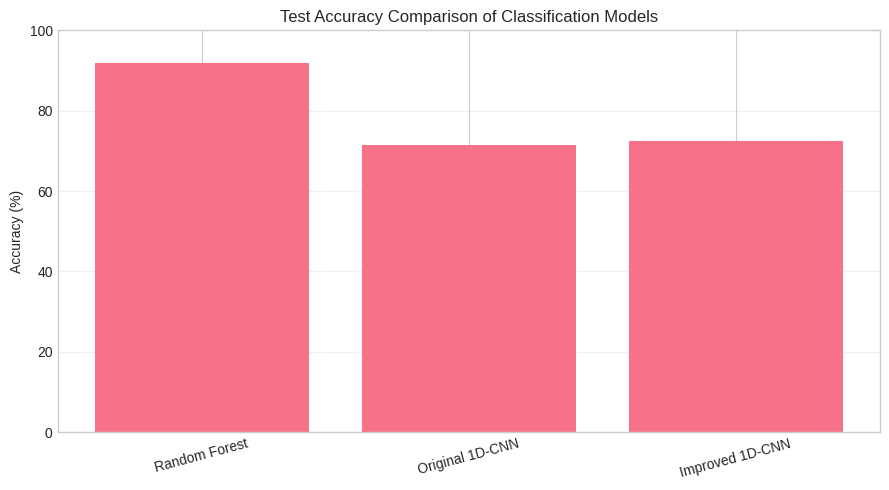

Final comparison saved successfully!


In [67]:
# STEP 22: THREE-MODEL COMPARISON

import pandas as pd
import matplotlib.pyplot as plt

final_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Original 1D-CNN",
        "Improved 1D-CNN"
    ],
    "Test Accuracy (%)": [
        rf_test_accuracy * 100,
        cnn_test_accuracy * 100,
        improved_accuracy * 100
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, cnn_probabilities),
        improved_auc
    ],
    "Training Time (seconds)": [
        rf_training_time,
        cnn_training_time,
        improved_cnn_time
    ]
})

display(final_comparison.round(4))

# Accuracy comparison graph
plt.figure(figsize=(9, 5))

plt.bar(
    final_comparison["Model"],
    final_comparison["Test Accuracy (%)"]
)

plt.title("Test Accuracy Comparison of Classification Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Save comparison
final_comparison.to_csv(
    "/content/Research_Results/final_model_comparison.csv",
    index=False
)

print("Final comparison saved successfully!")

In [68]:
# STEP 23: ROC CURVE COMPARISON

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

models = {
    "Random Forest": rf_probabilities,
    "Original 1D-CNN": cnn_probabilities,
    "Improved 1D-CNN": improved_probabilities
}

plt.figure(figsize=(9, 6))

for model_name, probabilities in models.items():
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/content/Research_Results/roc_curve_comparison.png",
    dpi=300
)
plt.show()

print("ROC curve saved successfully!")

[Plot removed to save space; the saved image is in results/original_run/]

ROC curve saved successfully!


In [69]:
# STEP 24: SAVE SHAP SUMMARY PLOT

import matplotlib.pyplot as plt
import shap
import os

os.makedirs("/content/Research_Results", exist_ok=True)

shap.summary_plot(
    shap_to_plot,
    X_shap,
    feature_names=selected_feature_names,
    show=False
)

plt.savefig(
    "/content/Research_Results/SHAP_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP summary plot saved successfully!")

[Plot removed to save space; the saved image is in results/original_run/]

SHAP summary plot saved successfully!


In [70]:
# STEP 25: SAVE LIME EXPLANATION

import matplotlib.pyplot as plt

fig = lime_explanation.as_pyplot_figure()

fig.savefig(
    "/content/Research_Results/LIME_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Also save interactive HTML explanation
lime_explanation.save_to_file(
    "/content/Research_Results/LIME_explanation.html"
)

print("LIME explanation saved successfully!")

[Plot removed to save space; the saved image is in results/original_run/]

LIME explanation saved successfully!


In [71]:
# STEP 26: CNN TRAINING HISTORY GRAPHS

import matplotlib.pyplot as plt
import os

save_path = "/content/Research_Results"
os.makedirs(save_path, exist_ok=True)

# Original CNN accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Original 1D-CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.savefig(f"{save_path}/original_cnn_accuracy.png", dpi=300)
plt.show()

# Original CNN loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Original 1D-CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig(f"{save_path}/original_cnn_loss.png", dpi=300)
plt.show()

# Improved CNN accuracy
plt.figure(figsize=(8, 5))
plt.plot(improved_history.history["accuracy"], label="Training Accuracy")
plt.plot(improved_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Improved 1D-CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.savefig(f"{save_path}/improved_cnn_accuracy.png", dpi=300)
plt.show()

# Improved CNN loss
plt.figure(figsize=(8, 5))
plt.plot(improved_history.history["loss"], label="Training Loss")
plt.plot(improved_history.history["val_loss"], label="Validation Loss")
plt.title("Improved 1D-CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig(f"{save_path}/improved_cnn_loss.png", dpi=300)
plt.show()

print("All training graphs saved successfully!")

[Plot removed to save space; the saved image is in results/original_run/]

[Plot removed to save space; the saved image is in results/original_run/]

[Plot removed to save space; the saved image is in results/original_run/]

[Plot removed to save space; the saved image is in results/original_run/]

All training graphs saved successfully!


In [72]:
# STEP 27: SAVE ALL RESEARCH WORK IN ONE ZIP

import os
import zipfile

results_path = "/content/Research_Results"

# Save improved CNN
improved_cnn.save(
    os.path.join(results_path, "improved_cnn.keras")
)

# Save final comparison
final_comparison.to_csv(
    os.path.join(results_path, "final_model_comparison.csv"),
    index=False
)

# Create ZIP backup
zip_path = "/content/Complete_Research_Results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(results_path):
        for file in files:
            full_path = os.path.join(root, file)
            relative_path = os.path.relpath(full_path, results_path)
            zipf.write(full_path, relative_path)

print("Research backup created successfully!")
print("ZIP location:", zip_path)

from google.colab import files
files.download(zip_path)

Research backup created successfully!
ZIP location: /content/Complete_Research_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>